# C2 — Train and explain your first model
## DataCo Regional Sales Analysis | Group 67
**Team:** Ian Spikin Thomas · Juan Pablo Molina  
**Course:** Business Intelligence (IIB423T-1) · Tomás Fontecilla  
**Original project repository:** https://github.com/ians513/Business-Intelligence  
**Model route:** **Clustering — K-means (the first algorithm in the class masterclass)**, applied to regional coverage/recording profiles; **not a demand forecast**.  
**Date:** 05 November 2026 · **Random seed:** 67

### Evidence and reproducibility
This notebook reads the supplied transaction-level file `DataCoSupplyChainDataset.csv` directly. It reproduces the W2 analytical population by validating essential fields and excluding `CANCELED` and `SUSPECTED_FRAUD`, then calculates the 23 region-level profiles, chronological KPI diagnostics, reference grouping and K-means results from those rows. The executed loading cell reports the file SHA-256 for traceability.  
**The clustering still uses regional aggregates rather than a region–category–month forecasting panel.** It is a narrower, honest step toward deciding which regions can be compared before making any commercial recommendation.

## 1. Task, scope, and response to W2 feedback
**Question:** Which observed DataCo regions share similar *recording/coverage profiles*, and which apparent differences in purchasing-intensity KPIs should be treated cautiously before commercial comparison?

**Data unit:** W2's source contained one *order item* per row. **This C2 model uses one *region* per row (23 rows)**: `items`, represented `orders`, first/last observed dates. The order-item rows per order feature is **not** the units-per-order KPI and should **not** be interpreted as demand.

**Decision:** group regions for a *comparability/data-quality review*, **not** recommend promotions or predict future sales. The raw order-item rows are available, but this C2 route intentionally aggregates them to regional recording/coverage profiles; a defensible supervised forecast would require a time-indexed target and a separate modeling design.

**Direct feedback mapping:**
- **W2 README (-1):** this notebook contains a reproducibility/source/version note in its opening and end sections. A separate README can be added to the GitHub repository; **do not add it to the C2 ZIP**, which accepts only notebooks, a PDF brief and a presentation.
- **October 2017:** review the stored pre-/post-October KPI diagnostic and note that an observed structural break **does not establish** a confirmed system migration.
- **Validation stability:** retain the W2 chronological train/validation/test evidence and region overlap checks. Because this C2 does **not forecast future demand**, the conditional forecast-stability instruction is addressed as a diagnostic rather than as predictive validation.

**Selected route:** **K-means**, the first clustering model taught in the supplied `BI_Trimestral_Unsupervised_Models_Masterclass.ipynb` (sections **2** and **13**). We follow the class workflow: specify the observation unit and numerical features, standardize, compare K values with silhouette, fit K-means using `n_init=20`, then describe clusters and compare them with a simple rule. K=3 emerges as the largest silhouette on these data and yields interpretable profiles. No supervised holdout, class labels or predictive accuracy apply to descriptive clustering.

In [41]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score, silhouette_score

SEED = 67
pd.set_option('display.max_rows', 50)
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})
print('C2 route: clustering; source: DataCoSupplyChainDataset.csv; seed:', SEED)

C2 route: clustering; source: DataCoSupplyChainDataset.csv; seed: 67


In [42]:
# Load the supplied transaction-level dataset and reproduce the W2 analytical population.
data_path = Path('DataCoSupplyChainDataset.csv')
if not data_path.is_file():
    raise FileNotFoundError('Place DataCoSupplyChainDataset.csv in the same folder as this notebook.')
df = pd.read_csv(data_path, encoding='ISO-8859-1', low_memory=False)
file_hash = hashlib.sha256(data_path.read_bytes()).hexdigest()
ORDER_DATE = 'order date (DateOrders)'
work = df.copy()
work[ORDER_DATE] = pd.to_datetime(work[ORDER_DATE], errors='coerce')
work['_status_norm'] = work['Order Status'].astype('string').str.strip().str.upper()
qty = pd.to_numeric(work['Order Item Quantity'], errors='coerce')
price = pd.to_numeric(work['Order Item Product Price'], errors='coerce')
disc_rate = pd.to_numeric(work['Order Item Discount Rate'], errors='coerce')
disc = pd.to_numeric(work['Order Item Discount'], errors='coerce')
sales = pd.to_numeric(work['Sales'], errors='coerce')
item_total = pd.to_numeric(work['Order Item Total'], errors='coerce')
expected_statuses = {'COMPLETE','PENDING_PAYMENT','PROCESSING','PENDING','CLOSED','ON_HOLD','SUSPECTED_FRAUD','CANCELED','PAYMENT_REVIEW'}
numeric_invalid = (qty.isna() | (qty <= 0) | (qty % 1 != 0) | price.isna() | (price < 0) | disc_rate.isna() | ~disc_rate.between(0,1) | disc.isna() | (disc < 0) | sales.isna() | (sales < 0) | item_total.isna() | (item_total < 0))
unexpected_status = ~work['_status_norm'].isin(expected_statuses) | work['_status_norm'].isna()
essential_valid = (work['Order Item Id'].notna() & ~work['Order Item Id'].duplicated(keep=False) & work['Order Id'].notna() & work[ORDER_DATE].notna() & work['Order Region'].notna() & work['Category Name'].notna() & ~numeric_invalid & ~unexpected_status)
commercial = work.loc[essential_valid & ~work['_status_norm'].isin(['CANCELED','SUSPECTED_FRAUD'])].copy()
regions = (commercial.groupby('Order Region').agg(first_date=(ORDER_DATE,'min'), last_date=(ORDER_DATE,'max'), items=('Order Item Id','size'), orders=('Order Id','nunique')).reset_index().sort_values('first_date').reset_index(drop=True))
assert len(regions) == 23
assert regions['items'].sum() == 172765
assert regions['orders'].sum() == 62897
assert (regions['items']>=regions['orders']).all()
regions['items_per_order'] = regions['items']/regions['orders']
regions['span_days'] = (regions['last_date']-regions['first_date']).dt.total_seconds()/86400
regions['log_orders'] = np.log10(regions['orders'])
regions['has_records_after_sep_2017'] = regions['last_date'].ge('2017-10-01')
display(regions[['Order Region','items','orders','items_per_order','span_days','has_records_after_sep_2017']].round(2))
print('Dataset:', data_path.as_posix(), '| rows:', len(df), '| SHA-256:', file_hash)
print('Audit: 23 regions, 172,765 eligible items, 62,897 represented orders. Values reproduced from the CSV.')

,Order Region,items,orders,items_per_order,span_days,has_records_after_sep_2017
0,Central America,27174,9001,3.02,894.59,False
1,South America,14184,4738,2.99,898.95,False
2,Caribbean,7951,2675,2.97,892.65,False
3,Northern Europe,9408,3564,2.64,894.59,True
4,Western Europe,25867,9563,2.70,894.53,True
5,Southern Europe,9030,3390,2.66,894.30,True
6,Eastern Asia,6973,3171,2.20,830.54,True
7,Southeast Asia,9136,4173,2.19,830.67,True
8,Oceania,9733,4175,2.33,830.64,True
9,South Asia,7455,3219,2.32,830.04,True


Dataset: DataCoSupplyChainDataset.csv | rows: 180519 | SHA-256: fa6d022ed437155e1a2f0378710602848703c8a7f203f7ff5d77805bf8480aa6
Audit: 23 regions, 172,765 eligible items, 62,897 represented orders. Values reproduced from the CSV.


## 2. October 2017 KPI break: observed vs. verified
**Primary KPI from W2:** `sum(Order Item Quantity) / nunique(Order Id)` in the eligible population (`CANCELED` and `SUSPECTED_FRAUD` excluded). It uses *recorded units* and *represented orders*, not order-item row counts. W2 found that orders after October 2017 are recorded very differently.

- **W2 chronological split** (order-level, non-overlapping): train 64% of orders, validation 16%, test 20%. Validation is **before October 2017**, whereas test crosses the break. W2 already inspected test for descriptive robustness; those numbers are not new model test metrics.
- **Within the reproduced test period:** the next code cell calculates the pre- and post-October KPI directly from the source rows and reports the share of test orders in the later period.
- **Status:** change in **observed order-item structure** is supported; the **cause or existence of a registration-system change is NOT verified** without system logs, data dictionary revision or owner confirmation. Therefore no causal or demand-drop claim is justified.

,split,orders,units,units_per_order,first_date,last_date
0,train,40254,266069,6.609753,2015-01-01 00:00:00,2017-01-06 16:50:00
1,validation,10063,65107,6.469939,2017-01-06 17:53:00,2017-07-10 00:17:00
2,test,12580,36415,2.894674,2017-07-10 00:38:00,2018-01-31 23:38:00


Train to validation: -2.12 % (descriptive KPI drift)
Within test, pre-/post-Oct 2017 KPI: 6.17 -> 1.05 units/order; post-Oct order share: 63.9%.


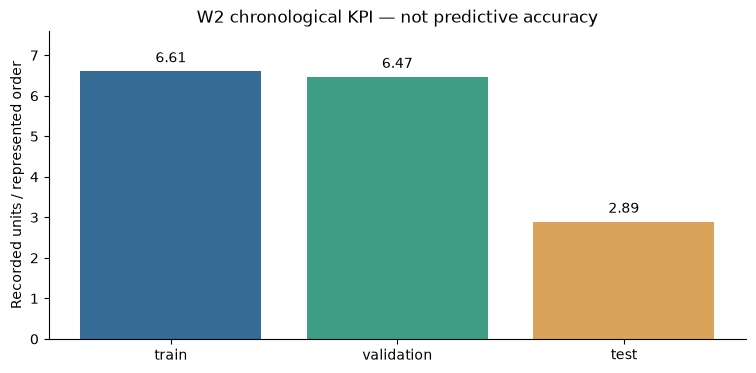

In [43]:
order_split = (commercial.groupby('Order Id').agg(order_date=(ORDER_DATE,'min')).reset_index().sort_values(['order_date','Order Id']))
train_end = int(len(order_split) * 0.64)
validation_end = int(len(order_split) * 0.80)
split_ids = {
    'train': order_split.iloc[:train_end]['Order Id'],
    'validation': order_split.iloc[train_end:validation_end]['Order Id'],
    'test': order_split.iloc[validation_end:]['Order Id'],
}
split_frames = {name: commercial.loc[commercial['Order Id'].isin(ids)].copy() for name, ids in split_ids.items()}
w2_split_kpi = pd.DataFrame([{
    'split': name,
    'orders': frame['Order Id'].nunique(),
    'units': frame['Order Item Quantity'].sum(),
    'units_per_order': frame['Order Item Quantity'].sum() / frame['Order Id'].nunique(),
    'first_date': frame[ORDER_DATE].min(),
    'last_date': frame[ORDER_DATE].max(),
} for name, frame in split_frames.items()])
display(w2_split_kpi)
test = split_frames['test']
test_pre_oct = test.loc[test[ORDER_DATE] < '2017-10-01']
test_post_oct = test.loc[test[ORDER_DATE] >= '2017-10-01']
pre_oct_kpi = test_pre_oct['Order Item Quantity'].sum() / test_pre_oct['Order Id'].nunique()
post_oct_kpi = test_post_oct['Order Item Quantity'].sum() / test_post_oct['Order Id'].nunique()
post_oct_order_share = test_post_oct['Order Id'].nunique() / test['Order Id'].nunique()
train_kpi = w2_split_kpi.loc[w2_split_kpi['split'].eq('train'),'units_per_order'].iloc[0]
validation_kpi = w2_split_kpi.loc[w2_split_kpi['split'].eq('validation'),'units_per_order'].iloc[0]
print('Train to validation:', round((validation_kpi/train_kpi-1)*100, 2), '% (descriptive KPI drift)')
print(f'Within test, pre-/post-Oct 2017 KPI: {pre_oct_kpi:.2f} -> {post_oct_kpi:.2f} units/order; post-Oct order share: {post_oct_order_share:.1%}.')
fig,ax=plt.subplots()
rects=ax.bar(w2_split_kpi['split'],w2_split_kpi['units_per_order'],color=['#356b95','#3f9c85','#dba35a'])
ax.bar_label(rects,fmt='%.2f',padding=4)
ax.set_ylim(0,7.6);ax.set_ylabel('Recorded units / represented order')
ax.set_title('W2 chronological KPI — not predictive accuracy')
plt.show()

### Regional windows and KPI comparability
The five regions with the largest retained recorded-unit totals have a **calendar-date intersection** but **no month with recorded transactions in all five**. A date-range intersection is therefore not an equivalent observation window. The table below recomputes the full-period, common-window and pre-October KPI values directly from the source rows. **Do not rank regions as commercial winners** from these values.

,Order Region,full_period,common_window,pre_oct2017
0,Central America,6.615,6.597,6.615
1,Western Europe,5.641,6.551,6.497
2,South America,6.538,6.386,6.538
3,Oceania,4.693,6.490,6.490
4,Northern Europe,5.488,6.720,6.328


Months with observations in all five regions during date-overlap window = 0


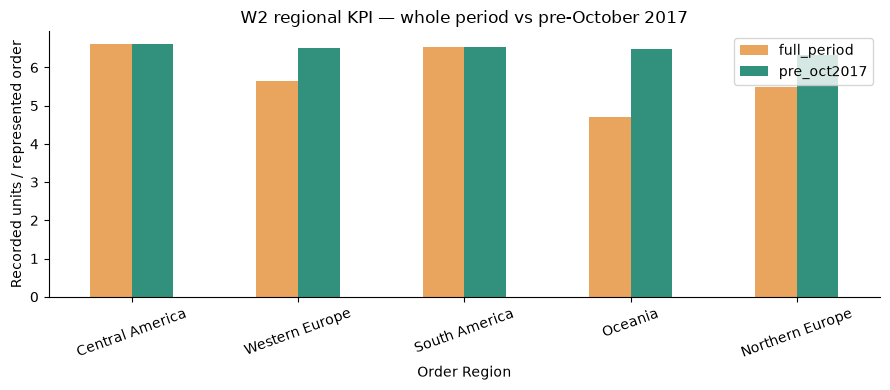

In [44]:
def region_units_per_order(frame):
    out = frame.groupby('Order Region').agg(units=('Order Item Quantity','sum'), orders=('Order Id','nunique'))
    return out['units'] / out['orders']
top5_regions = commercial.groupby('Order Region')['Order Item Quantity'].sum().nlargest(5).index.tolist()
top5_coverage = commercial.loc[commercial['Order Region'].isin(top5_regions)].groupby('Order Region').agg(first_date=(ORDER_DATE,'min'), last_date=(ORDER_DATE,'max'))
common_start = top5_coverage['first_date'].max()
common_end = top5_coverage['last_date'].min()
top5_full = commercial.loc[commercial['Order Region'].isin(top5_regions)]
top5_common = top5_full.loc[top5_full[ORDER_DATE].between(common_start, common_end, inclusive='both')]
top5_pre_oct = top5_full.loc[top5_full[ORDER_DATE] < '2017-10-01']
regional_kpi_w2 = pd.concat({
    'full_period': region_units_per_order(top5_full),
    'common_window': region_units_per_order(top5_common),
    'pre_oct2017': region_units_per_order(top5_pre_oct),
}, axis=1).loc[top5_regions].reset_index()
display(regional_kpi_w2.round(3))
common_months = top5_common.assign(order_month=top5_common[ORDER_DATE].dt.to_period('M')).groupby('order_month')['Order Region'].nunique()
months_all_five = int(common_months.eq(len(top5_regions)).sum())
print('Months with observations in all five regions during date-overlap window =', months_all_five)
ax=regional_kpi_w2.set_index('Order Region')[['full_period','pre_oct2017']].plot(kind='bar',color=['#e9a45e','#31917c'])
ax.set_ylabel('Recorded units / represented order')
ax.set_title('W2 regional KPI — whole period vs pre-October 2017')
ax.tick_params(axis='x',labelrotation=20)
plt.tight_layout();plt.show()

## 3. Clustering model: features, preparation and fixed settings
Each **region** is described by **three measures derived directly from the filtered source rows**, with no outcomes or post-decision fields:
1. `log_orders`: logarithm of represented order count, compressing volume differences (volume/coverage proxy).
2. `items_per_order`: order-item **rows** divided by represented orders (registration structure, **not** the units KPI).
3. `span_days`: first-to-last recorded date span (coverage *range*, **not** the number of active days/months).

Scale these three inputs with `StandardScaler` on all 23 profile rows, which is appropriate for **descriptive clustering** with no predictive validation/test split. Exclude the `has_records_after_sep_2017` flag from fitting; use it as an *interpretation check* to avoid hard-coding the answer.

**Course-aligned implementation:** the professor's masterclass explains the K-means objective (minimize within-cluster squared Euclidean distances) in section 2 and evaluates different `K` with `silhouette_score`, using `n_init=20`, in section 13. We reproduce that logic for **K=2,...,6**, then select the highest descriptive silhouette; `random_state=67` ensures reproducibility. K selection uses **only these 23 clustering rows**, not an external prediction test. Silhouette measures compactness/separation, **not predictive quality or the truth of a commercial explanation**.

**Simple reference (baseline):** sort regions by represented orders and divide them into low/middle/high terciles. Compare each K-means cluster with this rule on the **same 23 regions**. The two methods do not need identical labels.

In [45]:
FEATURES = ['log_orders','items_per_order','span_days']
scaler = StandardScaler()
X_scaled = scaler.fit_transform(regions[FEATURES])
# Adapted from class Masterclass, Section 13: compare K by silhouette.
k_diagnostics = []
for k in range(2, 7):
    candidate = KMeans(n_clusters=k, n_init=20, random_state=SEED)
    labels_k = candidate.fit_predict(X_scaled)
    k_diagnostics.append({
        'K': k,
        'silhouette': silhouette_score(X_scaled, labels_k),
        'inertia': candidate.inertia_
    })
k_table = pd.DataFrame(k_diagnostics)
display(k_table.round(4))
best_k = int(k_table.loc[k_table['silhouette'].idxmax(), 'K'])
print('Highest silhouette selects K =', best_k)
assert best_k == 3  # expected for the regional profiles reproduced from the source CSV
model = KMeans(n_clusters=best_k, random_state=SEED, n_init=20)
regions['cluster'] = model.fit_predict(X_scaled)
print('Selected silhouette score:', round(silhouette_score(X_scaled, regions['cluster']),4))
regions['simple_volume_rule'] = pd.qcut(
    regions['orders'].rank(method='first'), 3, labels=['Low','Mid','High']
)
print('Chosen parameters:',model.get_params())
print('Scale fitted on 23 descriptive region profiles, not W2 train/test orders.')
profiles=(regions.groupby('cluster').agg(
    n_regions=('Order Region','size'), median_orders=('orders','median'),
    mean_items_per_order=('items_per_order','mean'), mean_span_days=('span_days','mean'),
    n_tail_regions=('has_records_after_sep_2017','sum')
).round(2))
display(profiles)
display(regions[['Order Region','orders','items_per_order','span_days','cluster','simple_volume_rule']].sort_values(['cluster','orders']).round(2))
assert int(profiles['n_regions'].sum()) == 23

,K,silhouette,inertia
0,2,0.6125,21.3685
1,3,0.6235,11.8815
2,4,0.5959,5.5342
3,5,0.5827,3.6758
4,6,0.5394,2.9134


Highest silhouette selects K = 3
Selected silhouette score: 0.6235
Chosen parameters: {'algorithm': 'lloyd', 'copy_x': True, 'init': 'k-means++', 'max_iter': 300, 'n_clusters': 3, 'n_init': 20, 'random_state': 67, 'tol': 0.0001, 'verbose': 0}
Scale fitted on 23 descriptive region profiles, not W2 train/test orders.


,n_regions,median_orders,mean_items_per_order,mean_span_days,n_tail_regions
cluster,,,,,
0,13,1174.0,3.02,144.67,0
1,6,4151.0,2.83,894.94,3
2,4,3696.0,2.26,830.47,4


,Order Region,orders,items_per_order,span_days,cluster,simple_volume_rule
20,Central Asia,180,3.01,143.77,0,Low
21,Canada,291,3.12,141.90,0,Low
19,Southern Africa,380,2.89,143.73,0,Low
14,Central Africa,533,3.03,142.46,0,Low
22,East Africa,589,3.02,143.66,0,Low
15,North Africa,1013,3.05,145.52,0,Low
18,West Africa,1174,3.04,145.50,0,Low
16,Eastern Europe,1246,3.04,145.88,0,Low
10,South of USA,1280,3.01,145.82,0,Mid
12,US Center,1852,3.05,145.52,0,Mid


### Additional figure 1 — Selecting K with silhouette (class section 13)

The instructor's K-means workflow compares candidate values of `K=2` through `K=6` using **mean silhouette score**. The figure below uses the `k_table` already calculated above; it introduces **no new data or model**. Higher is better *for separation and compactness*, but silhouette does **not** prove commercial or causal validity. On these 23 region-level summaries, `K=3` has the highest score.

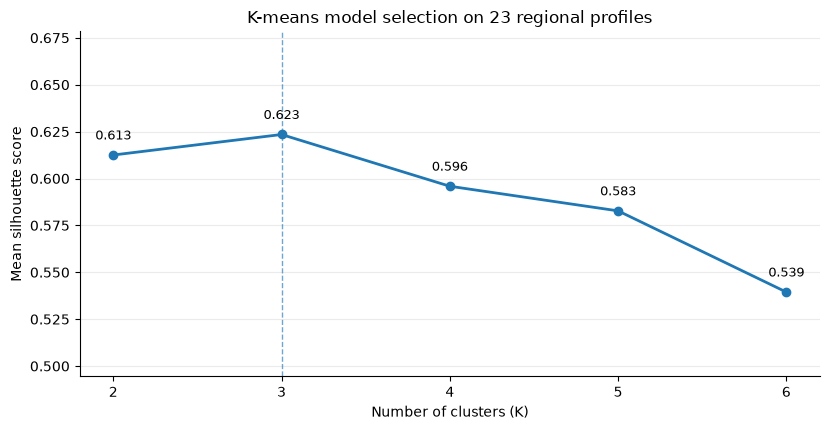

Maximum silhouette: K=3, score=0.6235


In [46]:
# Additional figure 1 — model selection from the existing class-style K table
fig, ax = plt.subplots(figsize=(8.4, 4.4))
ax.plot(k_table['K'], k_table['silhouette'], marker='o', linewidth=2)
for row in k_table.itertuples(index=False):
    ax.annotate(f'{row.silhouette:.3f}', (row.K, row.silhouette),
                xytext=(0, 9), textcoords='offset points',
                ha='center', va='bottom', fontsize=9)
ax.axvline(best_k, linestyle='--', linewidth=1, alpha=.65)
ax.set_xticks(k_table['K'])
ax.set_ylim(k_table['silhouette'].min() - .045, k_table['silhouette'].max() + .055)
ax.set_xlabel('Number of clusters (K)')
ax.set_ylabel('Mean silhouette score')
ax.set_title('K-means model selection on 23 regional profiles')
ax.grid(axis='y', alpha=.25)
fig.tight_layout()
plt.show()
print(f'Maximum silhouette: K={best_k}, score={k_table["silhouette"].max():.4f}')

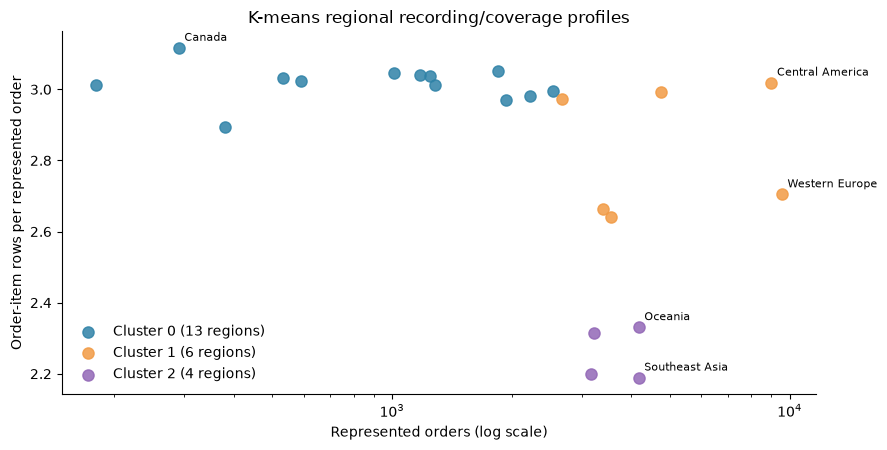

In [47]:
palette=['#2f82a7','#f19a44','#9267b6']
fig, ax=plt.subplots(figsize=(9,4.6))
for cluster, group in regions.groupby('cluster'):
    ax.scatter(group['orders'],group['items_per_order'],s=65,
               color=palette[cluster],label=f'Cluster {cluster} ({len(group)} regions)',alpha=.85)
for name in ['Oceania','Canada','Western Europe','Central America','Southeast Asia']:
    rr=regions.loc[regions['Order Region'].eq(name)]
    if not rr.empty:
        r=rr.iloc[0]; ax.annotate(name, (r['orders'],r['items_per_order']),xytext=(4,5),textcoords='offset points',fontsize=8)
ax.set_xscale('log');ax.set_xlabel('Represented orders (log scale)');ax.set_ylabel('Order-item rows per represented order')
ax.set_title('K-means regional recording/coverage profiles');ax.legend(frameon=False)
plt.tight_layout();plt.show()

### Additional figure 2 — Standardized K-means cluster profiles (class section 20)

The instructor's profile-comparison workflow studies **mean input characteristics by cluster**. Each cell here is the average **standardized value** (*z score*) of the original K-means inputs within that cluster; zero is the overall 23-region mean, not an absence of activity. This chart helps explain *why* the groups differ: order volume (`log10(orders)`), item-row structure (`items_per_order`), and temporal coverage (`span_days`). It does **not** show the sales-units KPI, and cluster numbers are labels, not rankings.

,log10(orders),order-item rows/order,coverage span (days)
cluster,,,
0,-0.67,0.61,-0.88
1,0.98,-0.02,1.21
2,0.70,-1.98,1.03


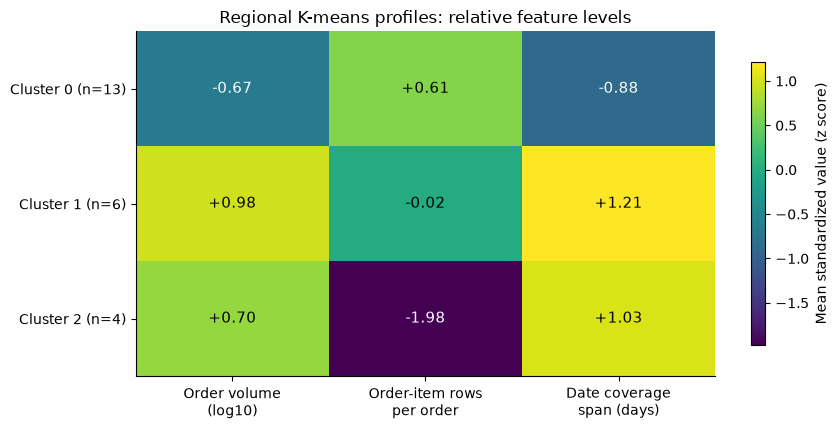

These are model inputs; they are NOT recorded units per order or sales forecasts.


In [48]:
# Additional figure 2 — heatmap of average standardized features in each cluster
z_frame = pd.DataFrame(X_scaled, columns=FEATURES, index=regions.index)
z_frame['cluster'] = regions['cluster'].to_numpy()
profile_z = z_frame.groupby('cluster')[FEATURES].mean()
display(profile_z.rename(columns={
    'log_orders': 'log10(orders)',
    'items_per_order': 'order-item rows/order',
    'span_days': 'coverage span (days)',
}).round(2))
fig, ax = plt.subplots(figsize=(8.8, 4.4))
image = ax.imshow(profile_z.to_numpy(), aspect='auto')
ax.set_xticks(range(len(FEATURES)))
ax.set_xticklabels(['Order volume\n(log10)', 'Order-item rows\nper order', 'Date coverage\nspan (days)'])
ax.set_yticks(range(len(profile_z.index)))
ax.set_yticklabels([f'Cluster {int(c)} (n={(regions["cluster"]==c).sum()})' for c in profile_z.index])
for i in range(profile_z.shape[0]):
    for j in range(profile_z.shape[1]):
        v = float(profile_z.iat[i,j])
        ax.text(j, i, f'{v:+.2f}', ha='center', va='center',
                color='white' if v < -.40 else 'black', fontsize=11)
cbar = fig.colorbar(image, ax=ax, shrink=.82)
cbar.set_label('Mean standardized value (z score)')
ax.set_title('Regional K-means profiles: relative feature levels')
fig.tight_layout()
plt.show()
print('These are model inputs; they are NOT recorded units per order or sales forecasts.')

## 4. Fair comparison with the simple grouping rule
The reference uses **only recorded order volume**. The model also incorporates item-level structure and calendar coverage range. Report group sizes, averages and the cross-tabulation. **Adjusted Rand Index (ARI)** is included solely to quantify agreement between *two clusterings*, **not classification accuracy against ground truth**. Positive ARI indicates some agreement beyond random labeling; it does **not** establish that one segmentation is more commercially accurate.

simple_volume_rule,Low,Mid,High
cluster,,,
0,8,5,0
1,0,1,5
2,0,1,3


ARI — agreement with reference, not accuracy: 0.361


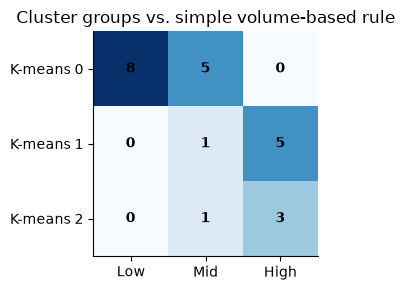

In [49]:
reference_comparison=pd.crosstab(regions['cluster'],regions['simple_volume_rule'])
display(reference_comparison)
ari=adjusted_rand_score(regions['simple_volume_rule'].cat.codes, regions['cluster'])
print('ARI — agreement with reference, not accuracy:',round(ari,3))
fig, ax=plt.subplots(figsize=(7,3))
im=ax.imshow(reference_comparison.values,cmap='Blues',vmin=0)
ax.set_xticks(range(3),reference_comparison.columns)
ax.set_yticks(range(3),[f'K-means {i}' for i in reference_comparison.index])
ax.set_title('Cluster groups vs. simple volume-based rule')
for (i,j),value in np.ndenumerate(reference_comparison.values):
    ax.text(j,i,str(value),ha='center',va='center',fontweight='bold')
plt.tight_layout();plt.show()

## 5. Evidence-based conclusion, limits and improvement
**Value added:** K-means finds regional recording/coverage profiles that are **not equivalent to splitting by volume alone**: they incorporate row structure and time span. W2 confirms that changes around October 2017 can heavily influence naive KPI comparisons. **The cluster numbers are nominal labels, not a performance ranking.**

**Important limitation:** although the notebook reads the raw item records, the model input is 23 **regional aggregates**, not a region–category–month panel. `span_days` cannot establish monthly overlap. The model is therefore **descriptive and exploratory**; it cannot establish cause, project demand, infer promotion effects, or certify any recording-system migration. Data period changes and unequal regional windows are confounders. No high predictive accuracy is claimed because this is clustering.

**Improvement:** obtain the original order-level dataset and the DataCo source-system/change-log documentation. Verify status filtering and the October 2017 order-line generation process. Rebuild a region–category–month panel, compare **truly shared active months**, and only then consider a forward-looking target with time-appropriate train/validation/test blocks and the same-record baseline.

**Practical interpretation:** treat the groups as an **audit priority queue** for further regional comparability checks, not as categories of high/low demand.

In [50]:
cluster_summary=profiles.reset_index()
for row in cluster_summary.itertuples(index=False):
    print(f'Cluster {row.cluster}: {row.n_regions} regions; median {row.median_orders:,.0f} orders; '
          f'mean {row.mean_items_per_order:.2f} item rows/order; '
          f'mean span {row.mean_span_days:.0f} days; '
          f'{int(row.n_tail_regions)} regions extend into Oct 2017 or later.')
print('Conclusion: profile segmentation, not a demand or commercial-success ranking.')

Cluster 0: 13 regions; median 1,174 orders; mean 3.02 item rows/order; mean span 145 days; 0 regions extend into Oct 2017 or later.
Cluster 1: 6 regions; median 4,151 orders; mean 2.83 item rows/order; mean span 895 days; 3 regions extend into Oct 2017 or later.
Cluster 2: 4 regions; median 3,696 orders; mean 2.26 item rows/order; mean span 830 days; 4 regions extend into Oct 2017 or later.
Conclusion: profile segmentation, not a demand or commercial-success ranking.


## 6. Source, version and contribution disclosure
**Direct sources of C2 results:** `DataCoSupplyChainDataset.csv`, read directly by this notebook, and the executed `W2_project.ipynb`, used to preserve the same validation and status-filtering rules. All regional aggregates, KPI diagnostics, clustering inputs and comparison results are calculated during execution from the supplied CSV.  
**Repository:** https://github.com/ians513/Business-Intelligence · **C2 deliverable version:** 1.1 · **Seed:** 67.

**Contribution record:**  
- **Ian Spikin Thomas:** connected the C2 notebook to the supplied transaction-level CSV; implemented the W2-aligned validation and filtering, regional aggregation, K selection, K-means model, simple-rule comparison, automated checks, and plots; and assembled the reproducible notebook.  
- **Juan Pablo Molina:** reviewed the task framing and method against the rubric and class material; checked the interpretation of the cluster profiles, reference comparison, limitations, and proposed improvement; and edited the brief and presentation for consistency with the notebook.  

**AI disclosure:** AI assistance was used to outline C2, draft reproducible code and plots, and edit the brief and presentation. The team verified those suggestions by executing the notebook against `DataCoSupplyChainDataset.csv`; checking the file hash and input shape; confirming the 23 regions and totals of 172,765 eligible items and 62,897 represented orders; running assertions for row count, totals, item/order consistency, K=3 selection, and complete cluster membership; rerunning K-means with the fixed seed 67 and `n_init=20`; checking that K=3 had the highest silhouette among K=2 to K=6; and reviewing the cluster profiles and ARI comparison with the simple volume rule to ensure they were described as exploratory agreement rather than predictive accuracy. Both members also checked that the notebook, brief, and presentation used the same figures, limitations, and conclusions. **Live AI use during the individual defense is prohibited** under the C2 rubric.

**References:** Group 67, *W2 — From Exploratory Analysis to Credible Validation* (executed notebook); Tomás Fontecilla, *C2 Train and explain your first model* (2026 rubric); *BI_Trimestral_Unsupervised_Models_Masterclass.ipynb* (provided class notes, sections 2 and 13, K-means algorithm and silhouette selection); DataCo Smart Supply Chain for Big Data Analysis (source dataset identified in W2; unverified source-system metadata).

**Additional class-aligned plots:** mean silhouette by K (masterclass section 13) and standardized cluster profiles (section 20), computed from the same 23 regional profiles derived from the source CSV and the fitted K-means clusters; these are visualization-only additions.
